In [1]:
import torch
from torch import nn
from torchinfo import summary
from torch.optim.lr_scheduler import CosineAnnealingLR
import torch.nn.functional as F
import matplotlib.pyplot as plt

from going_modular.custom_data_setup_main_train import LoadDataset
from going_modular import engine, utils
from going_modular import custom_data_setup_main_train
from going_modular.OneHeadModel import OneHeadModel

import helper_functions

In [2]:
allow_train = True
load_pre_train_model = True
freeze_encoder = False
EPOCHS = 40
BATCH_SIZE = 128
shrink_size = None
lr = 3e-3
weight_deacay = 1e-5
T_max = 13
eta_min = 3e-5
num_augs = 3
p_dropout = 0.4

crop_size = 240

# weights for alpha is inverse frequency

# alpha = torch.tensor([1/1805, 1/370, 1/999, 1/193, 1/295]) * 500 
alpha = torch.tensor([1, 1, 1, 1, 1])
gamma = 2
label_smoothing = 0.1

# alpha = [1] * 5
# alpha = [1/1805, 1/370, 1/999, 1/193, 1/295] * 500 

In [3]:
# Set matmul precision for TF32 usage on Ampere+ GPUs
torch.set_float32_matmul_precision('high')

# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

Augmentation

In [4]:
train_transforms = helper_functions.get_augmentation_train_transforms(num_augs, crop_size)
test_transforms = helper_functions.get_augmentation_test_transforms(crop_size)
no_transforms = helper_functions.get_augmentation_no_transforms(crop_size)

In [5]:
# load all dataloaders

train_dataloader, val_dataloader, class_names = custom_data_setup_main_train.create_train_val_dataloader(
    batch_size=BATCH_SIZE,
    train_transform=train_transforms,
    val_transform=test_transforms,
    shrink_size=shrink_size)

test_dataloader, class_names = custom_data_setup_main_train.create_test_dataloader(
    batch_size=BATCH_SIZE,
    test_transform=test_transforms, 
    shrink_size=shrink_size) 

exp_train_dataloader, class_names = custom_data_setup_main_train.create_train_dataloader(
    batch_size=BATCH_SIZE,
    train_transform=test_transforms,
    shrink_size=shrink_size)

MESSIDOR_dataloader, class_name = custom_data_setup_main_train.create_exotic_test_dataloader(
    batch_size=BATCH_SIZE,
    test_transform=test_transforms,
    dataset_name='MESSIDOR',
    shrink_size=shrink_size)   

IDRID_dataloader, class_name = custom_data_setup_main_train.create_exotic_test_dataloader(
    batch_size=BATCH_SIZE,
    test_transform=test_transforms,
    dataset_name='IDRID',
    shrink_size=shrink_size) 

APTOS_15_test_dataloader, class_name = custom_data_setup_main_train.create_exotic_test_dataloader(
    batch_size=BATCH_SIZE,
    test_transform=test_transforms,
    dataset_name='APTOS_15_test',
    shrink_size=shrink_size) 

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4285712].


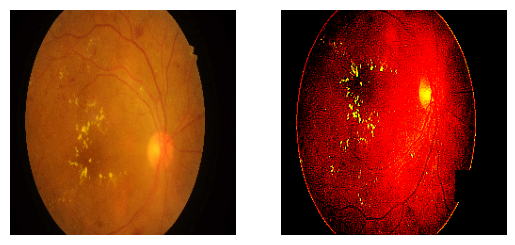

In [6]:
# plot some of the images to check applied augmentations

IDRID_image_folder = "../IDRID/Imagenes/Imagenes" 
IDRID_csv_file = "../IDRID/idrid_labels.csv"  

test_dataset_with_transform = LoadDataset(IDRID_image_folder, IDRID_csv_file, transform=train_transforms)
test_dataset_no_transform = LoadDataset(IDRID_image_folder, IDRID_csv_file, transform=no_transforms)

for i in range(1):
    img_2 = test_dataset_with_transform[i][0].permute(1, 2, 0)
    img_1 = test_dataset_no_transform[i][0].permute(1, 2, 0)
    fig, axes = plt.subplots(1, 2)
    axes[0].imshow(img_1.numpy())
    axes[1].imshow(img_2.numpy())
    axes[0].axis(False)
    axes[1].axis(False)
    plt.show()

In [7]:
model = OneHeadModel(device=device, p_dropout=p_dropout).to(device)

In [8]:
# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
def prepare_model():
    if load_pre_train_model:
        model.load_state_dict(torch.load("models/pre_train_model.pth", weights_only=True, map_location=device))

        for module in model.dense1:
            if isinstance(module, nn.Linear):
                # Apply He initialization to weights
                nn.init.kaiming_normal_(module.weight, mode='fan_in', nonlinearity='relu')
                # Initialize biases to zero (optional, common practice)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

        for module in model.classification_head:
            if isinstance(module, nn.Linear):
                # Apply He initialization to weights
                nn.init.kaiming_normal_(module.weight, mode='fan_in', nonlinearity='relu')
                # Initialize biases to zero (optional, common practice)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

In [9]:
# Print a summary using torchinfo (uncomment for actual output)
torch.manual_seed(33)
summary(model=model, 
        input_size=(32, 3, 240, 240), # make sure this is "input_size", not "input_shape"
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
) 

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
OneHeadModel (OneHeadModel)                                  [32, 3, 240, 240]    [32, 5]              --                   True
├─Sequential (encoder)                                       [32, 3, 240, 240]    [32, 1280, 8, 8]     --                   True
│    └─Conv2dNormActivation (0)                              [32, 3, 240, 240]    [32, 32, 120, 120]   --                   True
│    │    └─Conv2d (0)                                       [32, 3, 240, 240]    [32, 32, 120, 120]   864                  True
│    │    └─BatchNorm2d (1)                                  [32, 32, 120, 120]   [32, 32, 120, 120]   64                   True
│    │    └─SiLU (2)                                         [32, 32, 120, 120]   [32, 32, 120, 120]   --                   --
│    └─Sequential (1)                                        [32, 32, 120, 120]   [32, 16, 120

Custom Focal Loss function

In [10]:
# class FocalLoss_custom(torch.nn.Module):
#     def __init__(self, alpha, gamma, headType=None):
#         super(FocalLoss_custom, self).__init__()
#         self.alpha = alpha.to(device)
#         self.gamma = gamma
#         self.headType = headType
#     def forward(self, inputs, targets):
        
#         ce_loss = F.cross_entropy(inputs, targets, reduction='none', label_smoothing=0.1)
#         # apply class weights
#         # alpha is for the weight class, weights is the correct weight for each class and looks like this: tensor([a, b, c, d, a, ...])
#         weights = self.alpha.gather(0, targets)

#         pt = torch.exp(-ce_loss)
#         loss = (weights * ((1 - pt) ** self.gamma) * ce_loss)
#         # loss = (self.alpha * ((1 - pt) ** self.gamma) * ce_loss)
#         return loss.mean()

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, label_smoothing=0):
        super(FocalLoss, self).__init__()
        self.alpha = alpha.to(device)
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', label_smoothing=self.label_smoothing)
        pt = torch.exp(-ce_loss)
        loss = (self.alpha[targets] * (1 - pt) ** self.gamma * ce_loss).mean()
        return loss

In [12]:
# Define loss and optimizer

# from going_modular.focal_loss import FocalLoss

# weights are selected based on the APTOS 2019 distribution according to the paper
# weight = torch.tensor([3260/1750, 3260/270, 3260/840, 3260/140, 3260/260]) * 0.1
# weight = torch.tensor([1/1805, 1/370, 1/999, 1/193, 1/295]) * 500 

# weights.to(device)

# loss_fn_classification = nn.CrossEntropyLoss().to(device)
# loss_fn_classification = nn.CrossEntropyLoss(weight=weight).to(device)
# loss_fn_classification = FocalLoss_custom(headType='classification', alpha=alpha, gamma=gamma).to(device)
loss_fn_classification = FocalLoss(alpha=alpha, gamma=gamma, label_smoothing=label_smoothing).to(device)

optimizer = torch.optim.RAdam(model.parameters(), lr=lr, weight_decay=weight_deacay)

scheduler = CosineAnnealingLR(optimizer, T_max=T_max, eta_min=eta_min)

# from torch.optim.lr_scheduler import ReduceLROnPlateau
# scheduler = ReduceLROnPlateau(optimizer, 'min', patience=5)


First the encoder is frozen for 5 epochs...



  0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1, Learning Rate: 0.0029568485988776872
loss_classification_train: 3.1329 | loss_classification_val: 0.7498 | acc_classification_val: 0.5848

Epoch 2, Learning Rate: 0.0028299021980950165
loss_classification_train: 1.2587 | loss_classification_val: 0.5943 | acc_classification_val: 0.6335

Epoch 3, Learning Rate: 0.002626538461034085
loss_classification_train: 0.9514 | loss_classification_val: 1.2556 | acc_classification_val: 0.6374

Epoch 4, Learning Rate: 0.0023585761488957666
loss_classification_train: 0.8532 | loss_classification_val: 0.7029 | acc_classification_val: 0.6608

Epoch 5, Learning Rate: 0.0020415882572581653
loss_classification_train: 0.7670 | loss_classification_val: 0.4770 | acc_classification_val: 0.6608

Now the encoder will be trained...



  0%|          | 0/40 [00:00<?, ?it/s]


Epoch 1, Learning Rate: 0.0016939969701791546
loss_classification_train: 0.7411 | loss_classification_val: 0.4327 | acc_classification_val: 0.6745

Epoch 2, Learning Rate: 0.0013360030298208455
loss_classification_train: 0.6388 | loss_classification_val: 0.4548 | acc_classification_val: 0.6881

Epoch 3, Learning Rate: 0.0009884117427418349
loss_classification_train: 0.6170 | loss_classification_val: 0.4044 | acc_classification_val: 0.6862

Epoch 4, Learning Rate: 0.0006714238511042337
loss_classification_train: 0.5802 | loss_classification_val: 0.4322 | acc_classification_val: 0.6881

Epoch 5, Learning Rate: 0.00040346153896591474
loss_classification_train: 0.5727 | loss_classification_val: 0.4166 | acc_classification_val: 0.6842

Epoch 6, Learning Rate: 0.00020009780190498376
loss_classification_train: 0.5413 | loss_classification_val: 0.5842 | acc_classification_val: 0.6920

Epoch 7, Learning Rate: 7.315140112231277e-05
loss_classification_train: 0.5350 | loss_classification_val: 0.

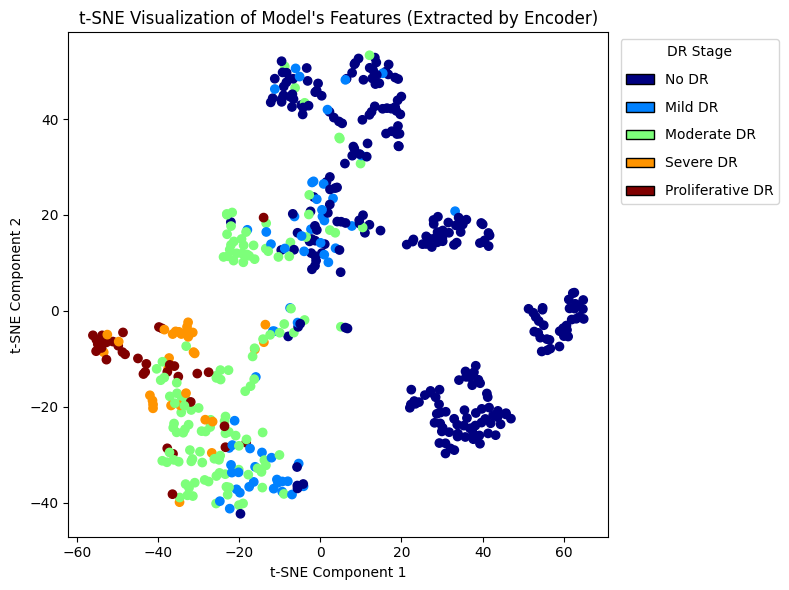

[INFO] Saving model to: models/main_train_model.pth
[INFO] Total training time: 560.858 seconds


In [13]:
# model = torch.compile(model)

if allow_train:
    # Set the random seeds
    torch.manual_seed(1404)
    torch.cuda.manual_seed(1404)

    # Start the timer
    from timeit import default_timer as timer 
    start_time = timer()

    # Setup training and save the results

    prepare_model() # restet model's weights to pre train for each fold

    print('\nFirst the encoder is frozen for 5 epochs...\n')

    # Freeze all base layers in the "features" section of the model 
    for param in model.encoder.parameters():
        param.requires_grad = False
    
    # training for 5 epochs to save pre train weights
    _, _ = engine.train(model=model,
                train_dataloader=train_dataloader,
                val_dataloader=val_dataloader,
                optimizer=optimizer,
                scheduler=scheduler,
                loss_fn_classification=loss_fn_classification,
                epochs=5,
                device=device)
    
    # resetting the scheduler
    # scheduler = CosineAnnealingLR(optimizer, T_max=T_max, eta_min=eta_min)
    # scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)

    print('\nNow the encoder will be trained...\n')
    
    # UnFreeze all base layers in the "features" section of the model 
    for param in model.encoder.parameters():
        param.requires_grad = True

    train_results, val_results = engine.train(model=model,
                train_dataloader=train_dataloader,
                val_dataloader=val_dataloader,
                optimizer=optimizer,
                scheduler=scheduler,
                loss_fn_classification=loss_fn_classification,
                epochs=EPOCHS,
                device=device)
    
    helper_functions.plot_t_SNE(model=model,
                            dataloader=val_dataloader,
                            NUM_ITER=2000)
    
    utils.save_model(model=model, target_dir='models', model_name=f'main_train_model.pth')


    # End the timer and print out how long it took
    end_time = timer()
    print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")
else:
    model.load_state_dict(torch.load('models/main_train_model.pth', weights_only=True, map_location=device))

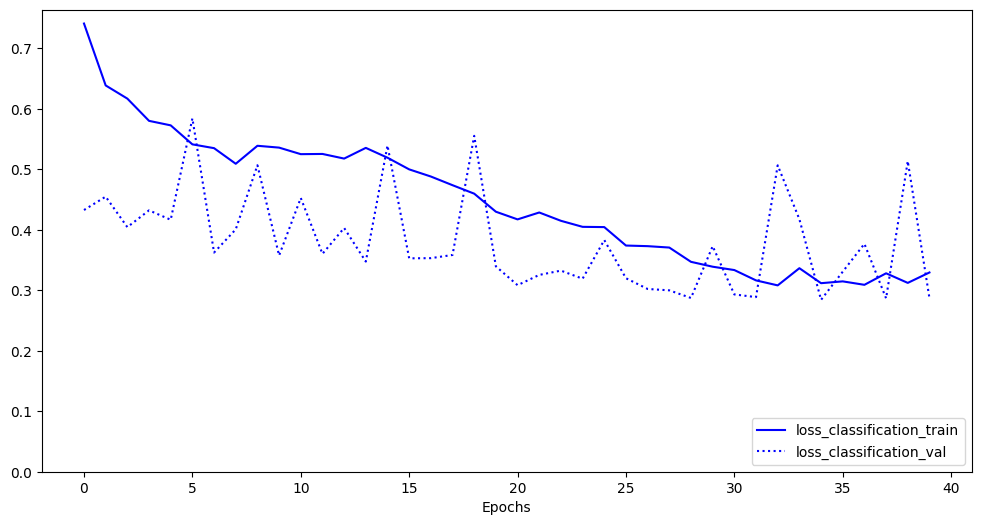

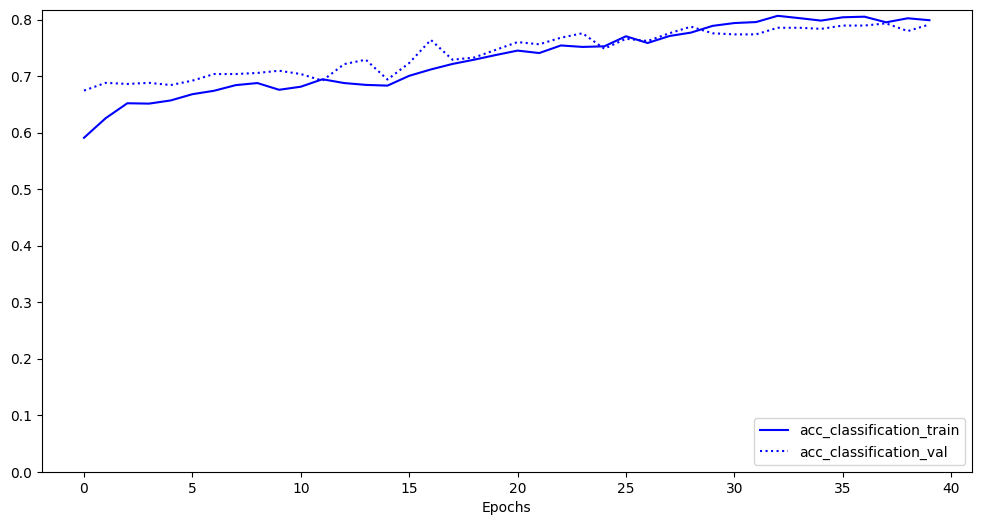

In [14]:
if allow_train:
    helper_functions.plot_loss_curves(train_results, val_results)
    helper_functions.plot_acc_curves(train_results, val_results)

per class precision: [0.97820163 0.71666667 0.75431034 0.42857143 0.65217391]
per class recall: [0.99445983 0.58108108 0.875      0.30769231 0.50847458]
per class f1_score: [0.98626374 0.64179104 0.81018519 0.35820896 0.57142857]
average scores >>> precision: 0.7059847975973087 | recall: 0.6533415597679177 | f1_score: 0.6735754985754985
accuracy: 0.844474761255116
QWK:  0.9054230213554574


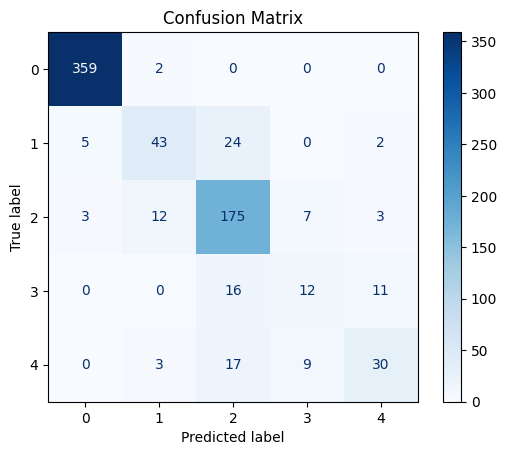

In [15]:
test_results = engine.test_step(model=model,
            dataloader=test_dataloader,
            device=device)

per class precision: [0.8760393  0.83127572 0.85154295 0.67777778 0.86770428]
per class recall: [0.99442299 0.38185255 0.87116041 0.64893617 0.74086379]
per class f1_score: [0.93148483 0.52331606 0.86123998 0.66304348 0.79928315]
average scores >>> precision: 0.8208680070338292 | recall: 0.7274471827104734 | f1_score: 0.7556735015814776
accuracy: 0.8552546045503792
QWK:  0.9286113264591335


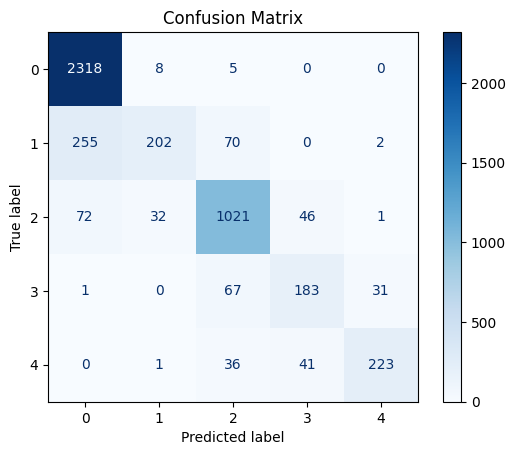

In [16]:
test_results = engine.test_step(model=model,
            dataloader=exp_train_dataloader,
            device=device)

per class precision: [0.75298507 0.57142857 0.88737201 0.77027027 0.86666667]
per class recall: [0.99213373 0.01481481 0.74927954 0.76       0.74285714]
per class f1_score: [0.8561731  0.02888087 0.8125     0.76510067 0.8       ]
average scores >>> precision: 0.7697445193288501 | recall: 0.6518170446447715 | f1_score: 0.6525309277934035
accuracy: 0.7775229357798165
QWK:  0.8312673602660151


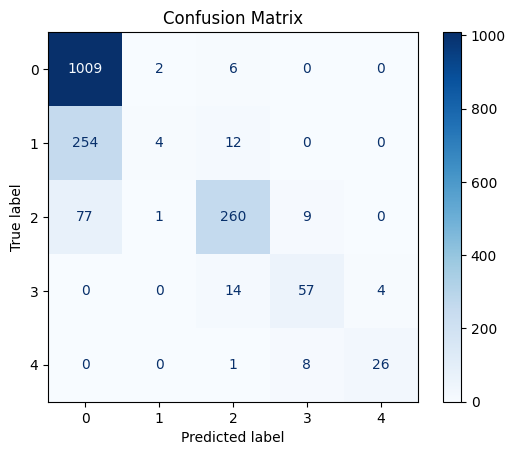

In [17]:
MESSIDOR_test_results = engine.test_step(model=model,
            dataloader=MESSIDOR_dataloader,
            device=device)

per class precision: [0.81528662 0.         0.81012658 0.65060241 0.8245614 ]
per class recall: [0.99224806 0.         0.82051282 0.64285714 0.734375  ]
per class f1_score: [0.8951049  0.         0.81528662 0.64670659 0.7768595 ]
average scores >>> precision: 0.6201154039259258 | recall: 0.6379986050770935 | f1_score: 0.6267915220534591
accuracy: 0.7846153846153846
QWK:  0.9118981577976945


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


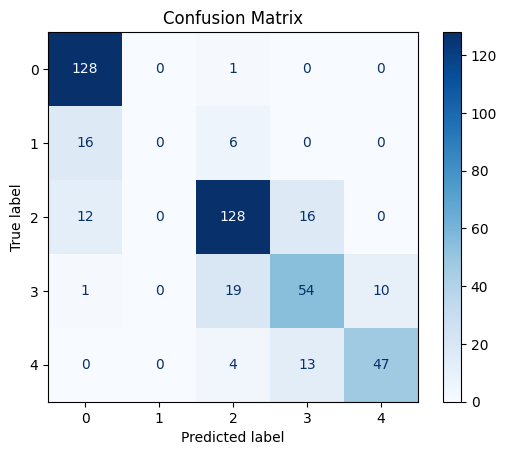

In [18]:
IDRID_test_results = engine.test_step(model=model,
            dataloader=IDRID_dataloader,
            device=device)

per class precision: [0.79674656 0.05956679 0.37742631 0.50920245 0.65107212]
per class recall: [0.93167733 0.01754386 0.26714159 0.06836903 0.27694859]
per class f1_score: [0.85894521 0.02710472 0.31284916 0.12055192 0.38859802]
average scores >>> precision: 0.4788028476559029 | recall: 0.31233607918767275 | f1_score: 0.34160980791560336
accuracy: 0.7356838883081978
QWK:  0.4307096409697434


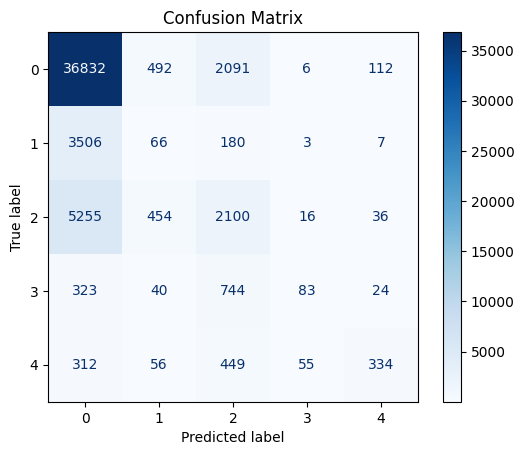

In [19]:
APTOS_15_test_results = engine.test_step(model=model,
            dataloader=APTOS_15_test_dataloader,
            device=device)

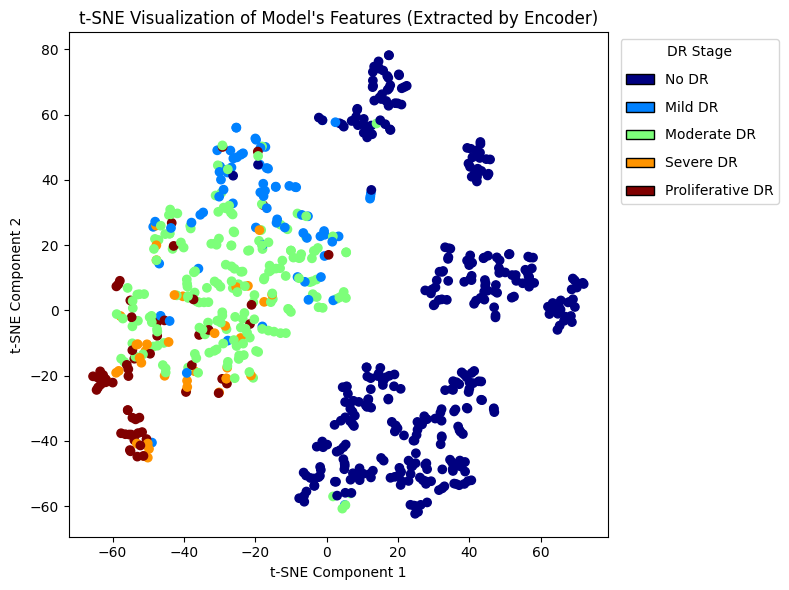

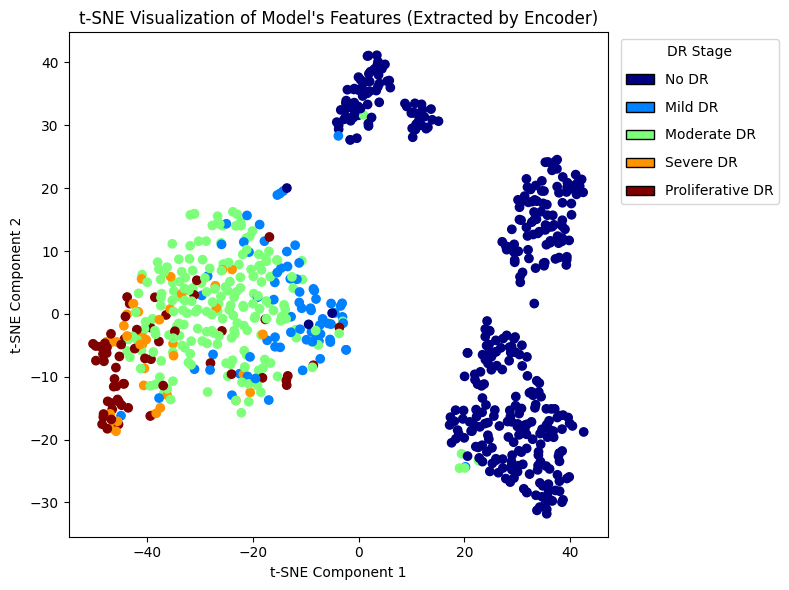

In [22]:
helper_functions.plot_t_SNE(model=model,
                        dataloader=test_dataloader,
                        perp_vals=[5, 20],
                        NUM_ITER=2000)